# Phase 4 — Persistency and Retention Analytics

## 1. Business question
How persistent is new business after 3, 6 and 13 months, where are policies being lost, and which portfolio characteristics are associated with stronger or weaker retention?

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

ROOT = Path.cwd()
OUT = ROOT / "data/processed/phase4"
execution = json.loads((OUT / "execution.json").read_text())
assert execution["validation_failures"] == 0
assert execution["as_of"] == "2026-09-01"


def read(name):
    return pd.read_csv(OUT / f"{name}.csv")


overall = read("overall_persistency")
cohort = read("cohort_persistency")
hierarchy = read("hierarchy_persistency")
product = read("product_persistency")
frequency = read("payment_frequency_persistency")
segments = read("customer_segment_persistency")
timing = read("lapse_timing")
payment = read("payment_behavior_summary")
display(Markdown(f"Validated SQL outputs loaded for fixed snapshot **{execution['as_of']}**."))

Validated SQL outputs loaded for fixed snapshot **2026-09-01**.

## 2. Persistency definition
Count persistency is persistent eligible policies divided by eligible policies. Premium persistency applies the same definition to annualized premium. Active, Grace and Reinstated are in force; Lapsed, Surrendered and Cancelled are not. Matured policies are shown separately and excluded from the denominator. Annualized premium is not cash or revenue.

## 3. Eligibility and anniversary rules
A policy enters a milestone denominator only when its 3-, 6- or 13-month anniversary is on or before 2026-09-01. Status is reconstructed from the latest event on or before that anniversary; later events and current policy status cannot revise history.

## 4. Overall scorecard

,milestone_months,eligible_policies,persistent_policies,count_persistency,eligible_annualized_premium,persistent_annualized_premium,premium_persistency,lapsed_count,surrendered_count,cancelled_count,matured_count
0,3,29492,29461,99.9%,8.928276e+10,8.917572e+10,99.9%,31,0,0,0
1,6,24980,24330,97.4%,7.546860e+10,7.343094e+10,97.3%,644,6,0,0
2,13,17206,15891,92.4%,5.205006e+10,4.794636e+10,92.1%,1121,194,0,0


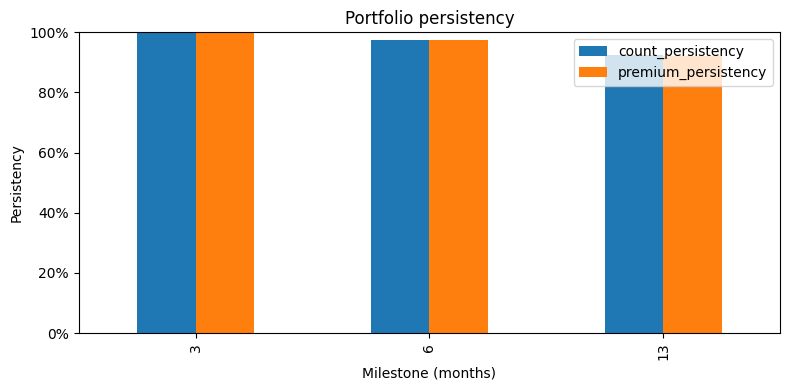

In [2]:
scorecard = overall[
    [
        "milestone_months",
        "eligible_policies",
        "persistent_policies",
        "count_persistency",
        "eligible_annualized_premium",
        "persistent_annualized_premium",
        "premium_persistency",
        "lapsed_count",
        "surrendered_count",
        "cancelled_count",
        "matured_count",
    ]
].copy()
scorecard["count_persistency"] = scorecard["count_persistency"].map(lambda x: f"{x:.1%}")
scorecard["premium_persistency"] = scorecard["premium_persistency"].map(lambda x: f"{x:.1%}")
display(scorecard)
ax = overall.set_index("milestone_months")[["count_persistency", "premium_persistency"]].plot(
    kind="bar", ylim=(0, 1), figsize=(8, 4), title="Portfolio persistency"
)
ax.set(xlabel="Milestone (months)", ylabel="Persistency")
ax.yaxis.set_major_formatter(lambda value, position: f"{value:.0%}")
plt.tight_layout()
plt.show()

## 5. Issue-cohort trends

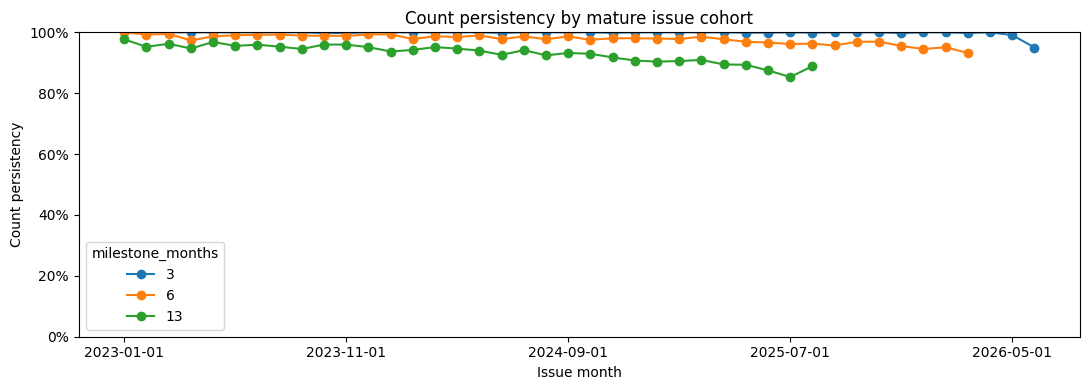

In [3]:
mature_cohorts = cohort[cohort["eligible_policies"] > 0].copy()
trend = mature_cohorts.pivot(
    index="issue_month", columns="milestone_months", values="count_persistency"
)
trend.plot(figsize=(11, 4), marker="o", title="Count persistency by mature issue cohort")
plt.xlabel("Issue month")
plt.ylabel("Count persistency")
plt.ylim(0, 1)
plt.gca().yaxis.set_major_formatter(lambda value, position: f"{value:.0%}")
plt.tight_layout()
plt.show()

## 6. Regional persistency

In [4]:
regions = hierarchy[(hierarchy["grain"] == "Region") & (hierarchy["milestone_months"] == 13)]
display(
    regions[
        ["region", "eligible_policies", "count_persistency", "premium_persistency"]
    ].sort_values("count_persistency")
)

,region,eligible_policies,count_persistency,premium_persistency
1205,Northern,3252,0.914207,0.910763
1199,Central,8427,0.924172,0.921814
1208,Western,2974,0.926026,0.923596
1202,Eastern,2553,0.930670,0.929425


## 7. Agency-unit persistency

In [5]:
units = hierarchy[(hierarchy["grain"] == "Unit") & (hierarchy["milestone_months"] == 13)]
display(
    units[
        ["agency_name", "region", "eligible_policies", "count_persistency", "premium_persistency"]
    ].sort_values("count_persistency")
)

,agency_name,region,eligible_policies,count_persistency,premium_persistency
1238,Lira,Northern,1619,0.903027,0.903295
1244,Fort Portal,Western,1770,0.907910,0.906182
1220,Wakiso,Central,1765,0.916147,0.914747
1217,Kampala North,Central,1514,0.918758,0.916980
1211,Kampala Central,Central,1503,0.918829,0.913873
1235,Gulu,Northern,1633,0.925291,0.918267
1232,Mbale,Eastern,1369,0.927684,0.922697
1223,Entebbe,Central,941,0.927736,0.927899
1226,Masaka,Central,1235,0.930364,0.924441
1229,Jinja,Eastern,1184,0.934122,0.937667


## 8. Agent persistency

In [6]:
agents = hierarchy[(hierarchy["grain"] == "Agent") & (hierarchy["milestone_months"] == 13)]
credible_agents = agents[agents["eligible_policies"] >= 10]
display(
    credible_agents[
        ["agent_id", "agency_name", "eligible_policies", "count_persistency", "premium_persistency"]
    ]
    .sort_values("count_persistency")
    .head(15)
)
display(
    Markdown(
        "Agent comparisons use at least 10 eligible policies for context; "
        "this presentation threshold is not a SQL metric rule."
    )
)

,agent_id,agency_name,eligible_policies,count_persistency,premium_persistency
863,A0018,Lira,14,0.714286,0.809160
659,A0026,Mbale,25,0.720000,0.708817
911,A0189,Lira,48,0.729167,0.707975
83,A0370,Kampala Central,40,0.750000,0.787770
374,A0221,Wakiso,16,0.750000,0.738717
938,A0290,Lira,41,0.780488,0.721490
344,A0097,Wakiso,28,0.785714,0.782194
68,A0293,Kampala Central,38,0.789474,0.784185
1115,A0155,Fort Portal,34,0.794118,0.865515
314,A0001,Wakiso,49,0.795918,0.823064


Agent comparisons use at least 10 eligible policies for context; this presentation threshold is not a SQL metric rule.

## 9. Product persistency

,product_name,eligible_policies,count_persistency,premium_persistency
11,Retirement Secure,3392,0.915979,0.915266
5,Family Income Plan,3409,0.922851,0.922083
2,Education Builder,3490,0.924355,0.922052
8,Protection Plus,3391,0.926865,0.925762
14,Savings Growth,3524,0.927639,0.925136


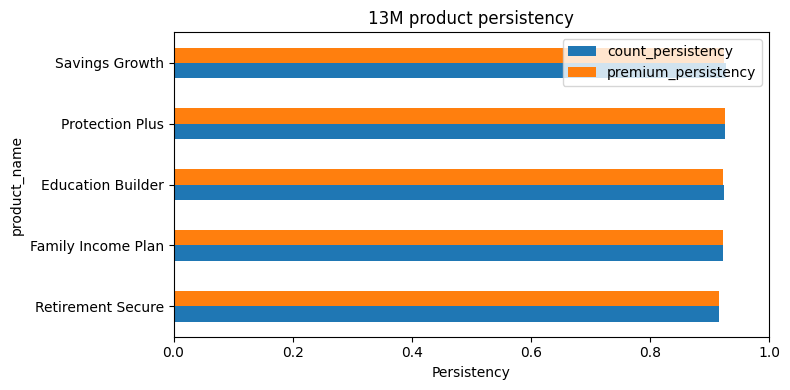

In [7]:
products_13 = product[product["milestone_months"] == 13].sort_values("count_persistency")
display(
    products_13[["product_name", "eligible_policies", "count_persistency", "premium_persistency"]]
)
products_13.set_index("product_name")[["count_persistency", "premium_persistency"]].plot(
    kind="barh", xlim=(0, 1), figsize=(8, 4), title="13M product persistency"
)
plt.xlabel("Persistency")
plt.tight_layout()
plt.show()

## 10. Payment-frequency persistency

In [8]:
display(
    frequency[frequency["milestone_months"] == 13][
        ["payment_frequency", "eligible_policies", "count_persistency", "premium_persistency"]
    ].sort_values("count_persistency")
)

,payment_frequency,eligible_policies,count_persistency,premium_persistency
8,Quarterly,2498,0.917134,0.912871
5,Monthly,11947,0.924249,0.920745
2,Annual,1681,0.925045,0.927424
11,Semi-Annual,1080,0.928704,0.934858


## 11. Customer segmentation

In [9]:
segment_13 = segments[segments["milestone_months"] == 13]
for segment_type, frame in segment_13.groupby("segment_type"):
    display(Markdown(f"**{segment_type}**"))
    display(
        frame[
            ["segment_value", "eligible_policies", "count_persistency", "premium_persistency"]
        ].sort_values("count_persistency")
    )

**Acquisition Channel**

,segment_value,eligible_policies,count_persistency,premium_persistency
14,Event,2846,0.918131,0.916744
5,Customer Referral,2878,0.921821,0.917470
17,Walk-in,2923,0.921998,0.924068
2,Agent Referral,2803,0.925437,0.923185
11,Employer/Group,2831,0.926881,0.921075
8,Digital,2925,0.927179,0.924363


**Age at Issue**

,segment_value,eligible_policies,count_persistency,premium_persistency
29,55+,4117,0.917658,0.916651
32,<25,2450,0.918776,0.908987
20,25-34,3698,0.924554,0.918954
23,35-44,3455,0.926483,0.928813
26,45-54,3486,0.930006,0.930201


**Customer Region**

,segment_value,eligible_policies,count_persistency,premium_persistency
38,Eastern,4484,0.920384,0.915051
35,Central,4719,0.923713,0.921729
44,Western,4616,0.924610,0.923324
41,Northern,3387,0.926188,0.925504


**Income Band**

,segment_value,eligible_policies,count_persistency,premium_persistency
50,2M-5M,3591,0.917015,0.914871
47,1M-2M,4594,0.919025,0.914381
53,500k-1M,4805,0.927784,0.925112
59,<500k,3064,0.927872,0.928965
56,5M+,1152,0.933160,0.930180


## 12. Lapse and other outcome timing

outcome_status,Lapsed,Surrendered
timing_band,,
0-<3 months,18,0
3-<6 months,789,6
6-<13 months,1125,345
13-<24 months,757,178
24+ months,307,74


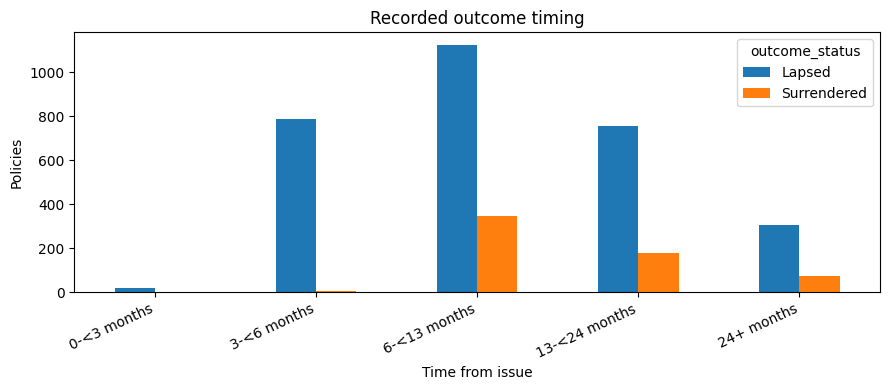

In [10]:
band_order = ["0-<3 months", "3-<6 months", "6-<13 months", "13-<24 months", "24+ months"]
timing_counts = (
    timing.groupby(["timing_band", "outcome_status"])
    .size()
    .unstack(fill_value=0)
    .reindex(band_order)
)
display(timing_counts)
timing_counts.plot(kind="bar", figsize=(9, 4), title="Recorded outcome timing")
plt.xlabel("Time from issue")
plt.ylabel("Policies")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## 13. Payment behaviour before milestone

In [11]:
display(
    payment[
        [
            "milestone_months",
            "outcome_group",
            "policies",
            "installments_due",
            "paid_rate",
            "late_rate",
            "missed_rate",
            "partial_rate",
            "payment_completion_rate",
        ]
    ]
)
display(
    Markdown(
        "These patterns are observed alongside milestone outcomes. They are descriptive "
        "and do not establish that payment behaviour caused an outcome."
    )
)

,milestone_months,outcome_group,policies,installments_due,paid_rate,late_rate,missed_rate,partial_rate,payment_completion_rate
0,3,Non-persistent,31,98,0.816327,0.122449,0.051020,0.010204,0.910603
1,3,Persistent,29461,92875,0.808022,0.122972,0.043564,0.025443,0.946770
2,6,Non-persistent,650,2583,0.801781,0.126597,0.046070,0.025552,0.938908
3,6,Persistent,24330,133256,0.808632,0.123327,0.043165,0.024877,0.946928
4,13,Non-persistent,1315,9015,0.794343,0.136106,0.044038,0.025513,0.943494
5,13,Persistent,15891,172162,0.808698,0.123227,0.042727,0.025348,0.946903


These patterns are observed alongside milestone outcomes. They are descriptive and do not establish that payment behaviour caused an outcome.

## 14. Management interpretation

In [12]:
m13 = overall.loc[overall["milestone_months"] == 13].iloc[0]
weak_product = products_13.iloc[0]
interpretation = [
    (
        f"**Observation →** Portfolio 13M count persistency is "
        f"**{m13['count_persistency']:.1%}** and premium persistency is "
        f"**{m13['premium_persistency']:.1%}**, across "
        f"**{int(m13['eligible_policies']):,}** eligible policies."
    ),
    (
        f"**Diagnosis →** {weak_product['product_name']} has the lowest observed 13M "
        "count persistency among products. Segment, unit and payment tables show "
        "where the observed difference is concentrated."
    ),
    (
        "**Business implication →** Count and premium persistency should be reviewed "
        "together because larger policies change the financial weighting of retention."
    ),
    (
        "**Possible management action →** Review the lowest-retention mature cohorts "
        "and adequately sized agent/unit groups, then examine pre-anniversary payment "
        "patterns before choosing a targeted service response."
    ),
]
display(Markdown("\n\n".join(interpretation)))

**Observation →** Portfolio 13M count persistency is **92.4%** and premium persistency is **92.1%**, across **17,206** eligible policies.

**Diagnosis →** Retirement Secure has the lowest observed 13M count persistency among products. Segment, unit and payment tables show where the observed difference is concentrated.

**Business implication →** Count and premium persistency should be reviewed together because larger policies change the financial weighting of retention.

**Possible management action →** Review the lowest-retention mature cohorts and adequately sized agent/unit groups, then examine pre-anniversary payment patterns before choosing a targeted service response.

## 15. Analytical limitations

- This is a fixed synthetic portfolio snapshot, not an insurer standard or external benchmark.
- Current agent unit and region are used because assignment history is unavailable.
- Annualized premium is not cash collection, profitability or revenue.
- Recorded status and payment events may not encode product-specific grace, accounting or regulatory rules.
- Comparisons are descriptive associations and do not establish causality or predict future lapse.